In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey,
    het_breuschpagan,
    het_white,
    linear_reset,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

In [16]:
# dataset
path = kagglehub.dataset_download("joebeachcapital/top-500-hollywood-movies-of-all-time")
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
movies_df = pd.read_csv(os.path.join(path, csv_file))

# Normalisasi nama kolom 
movies_df.columns = movies_df.columns.str.strip().str.replace(r"\s+", " ", regex=True)

# dummy genre: 1 = Horror, 0 = Not Horror (baseline)
movies_df["is_horror"] = (movies_df["horror"].str.strip().str.lower() == "horror").astype(int)

# dummy dekade: '2010's' (baseline)
decade_dummies = pd.get_dummies(movies_df["decade"], prefix="dec", dtype=int).drop(columns=["dec_2010's"])

ALPHA = 0.05


def format_persamaan(params, label_var):
    suku = [f"{params['const']:.4f}"]
    for col, nama in label_var.items():
        suku.append(f"{params[col]:+.4f}*({nama})")
    return " ".join(suku)


def keputusan_uji(pval, alpha=0.05):
    return "Tolak H0" if pval < alpha else "Gagal Tolak H0"

In [21]:
# matriks prediktor X, variabel terikat Y
X_init = sm.add_constant(pd.concat([movies_df[["budget (millions)", "is_horror"]], decade_dummies], axis=1))
y_init = movies_df["worldwide gross (m)"]

# model regresi linear berganda
model_init = sm.OLS(y_init, X_init).fit()

label_init = {
    "budget (millions)": "Budget",
    "is_horror": "is_horror",
    "dec_1970's": "dec_1970's",
    "dec_1980's": "dec_1980's",
    "dec_1990's": "dec_1990's",
    "dec_2000's": "dec_2000's",
    "dec_2020's": "dec_2020's",
}

print("Persamaan Model\n")
print(f"WorldwideGross_hat = {format_persamaan(model_init.params, label_init)}")
print(f"R-squared = {model_init.rsquared:.4f}\nAdj. R-squared = {model_init.rsquared_adj:.4f}\nN = {int(model_init.nobs)}")

Persamaan Model

WorldwideGross_hat = 214.7690 +2.9887*(Budget) -91.2628*(is_horror) +324.7199*(dec_1970's) +111.7769*(dec_1980's) +72.7133*(dec_1990's) -36.4757*(dec_2000's) -33.6235*(dec_2020's)
R-squared = 0.4099
Adj. R-squared = 0.4025
N = 562


In [26]:
# uji simultan: uji-F
print('Uji Simultan Model Awal\n')
print('H0: beta_1 = beta_2 = ... = beta_7 = 0')
print('H1: Minimal terdapat satu beta_j != 0 (j = 1, 2, ..., 7)')
kep_f_init = keputusan_uji(model_init.f_pvalue, ALPHA)
kes_f_init = (
    'Seluruh variabel bebas berpengaruh signifikan secara simultan terhadap worldwide gross.'
    if kep_f_init == 'Tolak H0'
    else 'Seluruh variabel bebas tidak berpengaruh signifikan secara simultan.'
)
print(f'Statistik F({int(model_init.df_model)}, {int(model_init.df_resid)}) = {model_init.fvalue:.4f} | p-value = {model_init.f_pvalue:.4e}')
print(f'Keputusan (alpha={ALPHA}) : {kep_f_init}')
print(f'Kesimpulan               : {kes_f_init}\n')

# uji parsial: uji-t
print('Uji Parsial Model Awal\n')
print('H0: beta_j = 0')
print("H1: beta_j != 0")
tabel_t_init = pd.DataFrame({
    'Koefisien': model_init.params,
    'Std_Error': model_init.bse,
    't_hitung': model_init.tvalues,
    'p_value': model_init.pvalues,
    'Keputusan': [keputusan_uji(p, ALPHA) for p in model_init.pvalues],
    'Kesimpulan': [
        'Berpengaruh signifikan secara parsial' if p < ALPHA else 'Tidak berpengaruh signifikan'
        for p in model_init.pvalues
    ],
})
print(tabel_t_init.to_string(float_format=lambda x: f'{x:.4f}'))

# uji asumsi klasik dan spesifikasi
print('\nuji asumsi klasik dan spesifikasi')
resid_init = model_init.resid

jb_stat, jb_pval, _, _ = jarque_bera(resid_init)
sw_stat, sw_pval = stats.shapiro(resid_init)
bp_lm, bp_pval, _, _ = het_breuschpagan(resid_init, X_init)
white_lm, white_pval, _, _ = het_white(resid_init, X_init)
reset_init = linear_reset(sm.OLS(y_init.to_numpy(), X_init.to_numpy()).fit(), power=3, use_f=True)
bg_lm, bg_pval, _, _ = acorr_breusch_godfrey(model_init, nlags=1)
dw_init = durbin_watson(resid_init)

tabel_asumsi = pd.DataFrame([
    {
        'Uji_Diagnostik': 'Normalitas (Jarque-Bera)',
        'Hipotesis_H0': 'Residual berdistribusi normal',
        'Statistik': f'JB = {jb_stat:.4f}',
        'p_value': f'{jb_pval:.4e}',
        'Keputusan': keputusan_uji(jb_pval, ALPHA),
        'Kesimpulan': 'Asumsi normalitas dilanggar' if jb_pval < ALPHA else 'Asumsi normalitas terpenuhi',
    },
    {
        'Uji_Diagnostik': 'Normalitas (Shapiro-Wilk)',
        'Hipotesis_H0': 'Residual berdistribusi normal',
        'Statistik': f'W = {sw_stat:.4f}',
        'p_value': f'{sw_pval:.4e}',
        'Keputusan': keputusan_uji(sw_pval, ALPHA),
        'Kesimpulan': 'Asumsi normalitas dilanggar' if sw_pval < ALPHA else 'Asumsi normalitas terpenuhi',
    },
    {
        'Uji_Diagnostik': 'Homoskedastisitas (Breusch-Pagan)',
        'Hipotesis_H0': 'Varians residual konstan',
        'Statistik': f'LM = {bp_lm:.4f}',
        'p_value': f'{bp_pval:.4e}',
        'Keputusan': keputusan_uji(bp_pval, ALPHA),
        'Kesimpulan': 'Terjadi heteroskedastisitas' if bp_pval < ALPHA else 'Homoskedastisitas terpenuhi',
    },
    {
        'Uji_Diagnostik': 'Homoskedastisitas (White)',
        'Hipotesis_H0': 'Varians residual konstan',
        'Statistik': f'LM = {white_lm:.4f}',
        'p_value': f'{white_pval:.4e}',
        'Keputusan': keputusan_uji(white_pval, ALPHA),
        'Kesimpulan': 'Terjadi heteroskedastisitas' if white_pval < ALPHA else 'Homoskedastisitas terpenuhi',
    },
    {
        'Uji_Diagnostik': 'Linearitas (Ramsey RESET)',
        'Hipotesis_H0': 'Spesifikasi linear tepat',
        'Statistik': f'F = {reset_init.fvalue:.4f}',
        'p_value': f'{reset_init.pvalue:.4e}',
        'Keputusan': keputusan_uji(reset_init.pvalue, ALPHA),
        'Kesimpulan': 'Bentuk linear tidak tepat (non-linear)' if reset_init.pvalue < ALPHA else 'Bentuk linear tepat',
    },
    {
        'Uji_Diagnostik': 'Non-Autokorelasi (Breusch-Godfrey)',
        'Hipotesis_H0': 'Tidak ada autokorelasi lag-1',
        'Statistik': f'LM = {bg_lm:.4f} (DW={dw_init:.4f})',
        'p_value': f'{bg_pval:.4e}',
        'Keputusan': keputusan_uji(bg_pval, ALPHA),
        'Kesimpulan': 'Terdapat korelasi serial indeks baris' if bg_pval < ALPHA else 'Bebas autokorelasi',
    },
])
print(tabel_asumsi.to_string(index=False))

# multikolinearitas (VIF)
vif_init = pd.DataFrame({
    'Variabel': X_init.columns,
    'VIF': [variance_inflation_factor(X_init.values, i) for i in range(X_init.shape[1])],
})
vif_init['Kesimpulan'] = np.where(vif_init['VIF'] < 10, 'Bebas multikolinearitas (VIF < 10)', 'Terindikasi multikolinearitas')
print('\nMultikolinearitas (VIF)')
print(vif_init.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

Uji Simultan Model Awal

H0: beta_1 = beta_2 = ... = beta_7 = 0
H1: Minimal terdapat satu beta_j != 0 (j = 1, 2, ..., 7)
Statistik F(7, 554) = 54.9794 | p-value = 1.4831e-59
Keputusan (alpha=0.05) : Tolak H0
Kesimpulan               : Seluruh variabel bebas berpengaruh signifikan secara simultan terhadap worldwide gross.

Uji Parsial Model Awal

H0: beta_j = 0
H1: beta_j != 0
                   Koefisien  Std_Error  t_hitung  p_value       Keputusan                             Kesimpulan
const               214.7690    27.9577    7.6819   0.0000        Tolak H0  Berpengaruh signifikan secara parsial
budget (millions)     2.9887     0.1780   16.7889   0.0000        Tolak H0  Berpengaruh signifikan secara parsial
is_horror           -91.2628    46.2827   -1.9719   0.0491        Tolak H0  Berpengaruh signifikan secara parsial
dec_1970's          324.7199   140.4817    2.3115   0.0212        Tolak H0  Berpengaruh signifikan secara parsial
dec_1980's          111.7769    75.3768    1.4829  

In [13]:
# Transformasi logaritma natural untuk mengatasi non-linearitas dan skewness
movies_df["log_worldwide_gross"] = np.log(movies_df["worldwide gross (m)"])
movies_df["log_budget"] = np.log(movies_df["budget (millions)"])

# Penyusunan matriks prediktor X dan variabel terikat y pada skala log-log
X_final = sm.add_constant(pd.concat([movies_df[["log_budget", "is_horror"]], decade_dummies], axis=1))
y_final = movies_df["log_worldwide_gross"]

# Fitting model OLS dengan kovarians kekar HC3 (Heteroskedasticity-Consistent)
model_final_hc3 = sm.OLS(y_final, X_final).fit(cov_type="HC3")

label_final = {
    "log_budget": "ln(Budget)",
    "is_horror": "is_horror",
    "dec_1970's": "dec_1970's",
    "dec_1980's": "dec_1980's",
    "dec_1990's": "dec_1990's",
    "dec_2000's": "dec_2000's",
    "dec_2020's": "dec_2020's",
}

rhs_final = format_persamaan(model_final_hc3.params, label_final)

print("=== PERSAMAAN EKSPLISIT MODEL AKHIR (LOG-LOG HC3) ===")
print(f"Bentuk Log-Linear  :\nln(WorldwideGross)_hat = {rhs_final}")
print(f"\nBentuk Eksponensial:\nWorldwideGross_hat     = exp({rhs_final})")
print(f"\nR-squared = {model_final_hc3.rsquared:.4f} | Adj. R-squared = {model_final_hc3.rsquared_adj:.4f} | AIC = {model_final_hc3.aic:.2f}")

=== PERSAMAAN EKSPLISIT MODEL AKHIR (LOG-LOG HC3) ===
Bentuk Log-Linear  :
ln(WorldwideGross)_hat = 3.9515 +0.4886*(ln(Budget)) +0.1370*(is_horror) +1.1191*(dec_1970's) +0.4786*(dec_1980's) +0.2233*(dec_1990's) -0.0150*(dec_2000's) -0.0414*(dec_2020's)

Bentuk Eksponensial:
WorldwideGross_hat     = exp(3.9515 +0.4886*(ln(Budget)) +0.1370*(is_horror) +1.1191*(dec_1970's) +0.4786*(dec_1980's) +0.2233*(dec_1990's) -0.0150*(dec_2000's) -0.0414*(dec_2020's))

R-squared = 0.6613 | Adj. R-squared = 0.6570 | AIC = 747.63


In [15]:
# --- A. Uji Simultan (Uji-F Wald Robust) ---
print("=== A. UJI SIMULTAN (UJI-F WALD ROBUST) MODEL AKHIR ===")
print("H0 : beta_1 = beta_2 = ... = beta_7 = 0")
print("H1 : Minimal terdapat satu beta_j != 0 (j = 1, 2, ..., 7)")
kep_f_fin = keputusan_uji(model_final_hc3.f_pvalue, ALPHA)
kes_f_fin = (
    "Seluruh variabel bebas berpengaruh signifikan secara simultan terhadap ln(WorldwideGross)."
    if kep_f_fin == "Tolak H0"
    else "Seluruh variabel bebas tidak berpengaruh signifikan secara simultan."
)
print(f"Statistik F({int(model_final_hc3.df_model)}, {int(model_final_hc3.df_resid)}) = {model_final_hc3.fvalue:.4f} | p-value = {model_final_hc3.f_pvalue:.4e}")
print(f"Keputusan (alpha={ALPHA}) : {kep_f_fin}")
print(f"Kesimpulan               : {kes_f_fin}\n")

# --- B. Uji Parsial (Uji-z Robust HC3) ---
print("=== B. UJI PARSIAL (UJI-z ROBUST HC3) MODEL AKHIR ===")
print("H0 : beta_j = 0 | H1 : beta_j != 0")
efek_persen = (np.exp(model_final_hc3.params) - 1) * 100
efek_persen.loc[["const", "log_budget"]] = np.nan

tabel_z_final = pd.DataFrame({
    "Koefisien": model_final_hc3.params,
    "Std_Err_HC3": model_final_hc3.bse,
    "z_hitung": model_final_hc3.tvalues,
    "p_value": model_final_hc3.pvalues,
    "Keputusan": [keputusan_uji(p, ALPHA) for p in model_final_hc3.pvalues],
    "Efek_Persen (%)": efek_persen,
    "Kesimpulan": [
        "Berpengaruh signifikan secara parsial" if p < ALPHA else "Tidak berpengaruh signifikan"
        for p in model_final_hc3.pvalues
    ],
})
print(tabel_z_final.to_string(float_format=lambda x: f"{x:.4f}"))

# --- C. Joint Wald Test Variabel Dummy Dekade ---
print("\n=== C. JOINT WALD TEST VARIABEL DUMMY DEKADE ===")
print("H0 : beta_dec_1970's = beta_dec_1980's = beta_dec_1990's = beta_dec_2000's = beta_dec_2020's = 0")
print("H1 : Minimal ada satu koefisien dummy dekade != 0")
wald_dec = model_final_hc3.wald_test(
    ["dec_1970's = 0", "dec_1980's = 0", "dec_1990's = 0", "dec_2000's = 0", "dec_2020's = 0"],
    scalar=True,
)
kep_wald = keputusan_uji(wald_dec.pvalue, ALPHA)
kes_wald = (
    "Blok dummy dekade berpengaruh signifikan secara bersama-sama dan dipertahankan sebagai kontrol."
    if kep_wald == "Tolak H0"
    else "Blok dummy dekade tidak berpengaruh signifikan secara bersama-sama."
)
print(f"Statistik F = {wald_dec.statistic:.4f} | p-value = {wald_dec.pvalue:.4e}")
print(f"Keputusan (alpha={ALPHA}) : {kep_wald}")
print(f"Kesimpulan               : {kes_wald}")

=== A. UJI SIMULTAN (UJI-F WALD ROBUST) MODEL AKHIR ===
H0 : beta_1 = beta_2 = ... = beta_7 = 0
H1 : Minimal terdapat satu beta_j != 0 (j = 1, 2, ..., 7)
Statistik F(7, 554) = 31.9103 | p-value = 3.1270e-37
Keputusan (alpha=0.05) : Tolak H0
Kesimpulan               : Seluruh variabel bebas berpengaruh signifikan secara simultan terhadap ln(WorldwideGross).

=== B. UJI PARSIAL (UJI-z ROBUST HC3) MODEL AKHIR ===
H0 : beta_j = 0 | H1 : beta_j != 0
            Koefisien  Std_Err_HC3  z_hitung  p_value       Keputusan  Efek_Persen (%)                             Kesimpulan
const          3.9515       0.1837   21.5156   0.0000        Tolak H0              NaN  Berpengaruh signifikan secara parsial
log_budget     0.4886       0.0416   11.7364   0.0000        Tolak H0              NaN  Berpengaruh signifikan secara parsial
is_horror      0.1370       0.1037    1.3214   0.1864  Gagal Tolak H0          14.6872           Tidak berpengaruh signifikan
dec_1970's     1.1191       0.1992    5.6176   

=== RINGKASAN ESTIMASI PARAMETER MODEL AWAL (MATRIKS OLS) ===
   Parameter   Koefisien   Std_Error  t_hitung  p_value
    Intersep -398.714955 1921.542446 -0.207497 0.836184
      budget    2.123561    0.042932 49.463577 0.000000
       tahun    0.223998    0.951305  0.235464 0.814491
genre_Comedy  -32.562202    7.120571 -4.572976 0.000019
 genre_Drama  -31.485068    6.369235 -4.943304 0.000005

R-squared   : 0.9713
F-hitung    : 634.7240 (p-value: 0.0000e+00)
JKT / JKR / JKS : 1568001.56 / 1523011.20 / 44990.36

=== HASIL DIAGNOSTIK ASUMSI KLASIK ===
Indeks Pencilan (|e*| > 3) : []
Uji Normalitas KS          : stat=0.0782, p-val=0.6821
Uji Normalitas Shapiro     : stat=0.9806, p-val=0.2636
Statistik Durbin-Watson    : 2.0972

--- Uji Homoskedastisitas (Korelasi Rank Spearman) ---
    Variabel  r_spearman  t_hitung  p_value
      budget   -0.093343 -0.827995 0.410199
       tahun    0.033939  0.299910 0.765044
genre_Comedy   -0.086257 -0.764649 0.446788
 genre_Drama   -0.051234 -0.4530

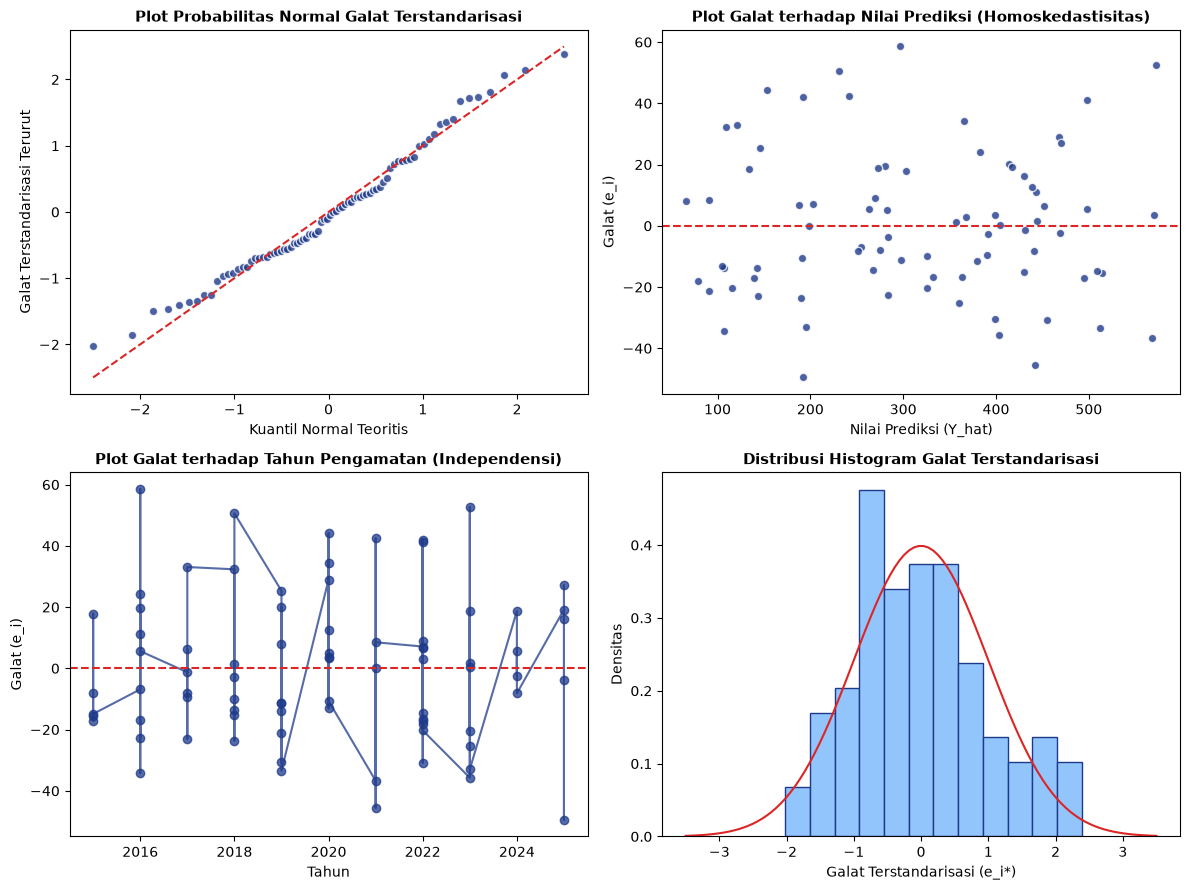


=== PENCARIAN LAMBDA OPTIMAL METODE BOX-COX ===
 lambda        JKS_W
  -1.00 1.459307e+06
  -0.75 8.978127e+05
  -0.50 5.535291e+05
  -0.25 3.405825e+05
   0.00 2.084308e+05
   0.25 1.271353e+05
   0.50 7.895033e+04
   0.75 5.349614e+04
   1.00 4.499036e+04
Lambda Optimal (JKS Terkecil): 1.0

R-squared Model Log-Log    : 0.9510
R-squared Model WLS        : 0.9708
R-squared Model Polinomial : 0.9719


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ==============================================================================
# 1. KONFIGURASI GLOBAL VISUALISASI
# ==============================================================================
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Roboto Condensed', 'DejaVu Sans']
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10


# ==============================================================================
# 2. PERSIAPAN DATA & ENCODING VARIABEL DUMMY (POKOK BAHASAN VII)
# ==============================================================================
def load_and_prepare_data(filepath=None):
    """
    Memuat dataset dan melakukan encoding k-1 variabel dummy untuk 'genre'.
    Ganti bagian simulasi dengan pd.read_csv(filepath) atau pd.read_excel(filepath).
    """
    if filepath:
        df = pd.read_csv(filepath)
    else:
        # Data simulasi sebagai template eksekusi
        rng = np.random.default_rng(42)
        n_sim = 80
        budget = rng.uniform(10, 250, n_sim)
        tahun = rng.integers(2015, 2026, n_sim)
        genre = rng.choice(['Action', 'Drama', 'Comedy'], size=n_sim)
        pendapatan = (
            15.0
            + 2.1 * budget
            + 1.2 * (tahun - 2015)
            + np.where(genre == 'Action', 35.0, np.where(genre == 'Comedy', 12.0, 0.0))
            + rng.normal(0, 25.0, n_sim)
        )
        df = pd.DataFrame({
            'pendapatan': pendapatan,
            'budget': budget,
            'tahun': tahun,
            'genre': genre
        })

    # Urutkan berdasarkan tahun untuk validitas uji autokorelasi Durbin-Watson
    df = df.sort_values(by='tahun').reset_index(drop=True)

    # Bentuk k-1 variabel dummy (kategori pertama menjadi grup dasar / referensi)
    df_encoded = pd.get_dummies(df, columns=['genre'], drop_first=True, dtype=float)

    Y = df_encoded['pendapatan'].values
    X_features = df_encoded.drop(columns=['pendapatan'])
    feature_names = ['Intersep'] + list(X_features.columns)

    # Susun matriks desain X berukuran n x p dengan kolom pertama bernilai 1
    X_mat = np.column_stack([np.ones(len(df_encoded)), X_features.values])

    return df, X_features, X_mat, Y, feature_names


# ==============================================================================
# 3. ESTIMASI MATRIKS OLS & UJI SIGNIFIKANSI (POKOK BAHASAN IV & V)
# ==============================================================================
def fit_ols_matrix(X_mat, Y, feature_names):
    """
    Menghitung estimator beta = (X^T X)^(-1) X^T Y, dekomposisi ANAVA,
    koefisien determinasi R^2, serta uji simultan F dan uji parsial t.
    """
    n, p = X_mat.shape
    k = p - 1  # Jumlah prediktor (termasuk variabel dummy)

    # Operasi matriks inti
    XTX = X_mat.T @ X_mat
    XTX_inv = np.linalg.inv(XTX)
    XTY = X_mat.T @ Y
    beta_hat = XTX_inv @ XTY

    # Nilai prediksi dan vektor galat (residual)
    Y_hat = X_mat @ beta_hat
    e = Y - Y_hat

    # Dekomposisi Jumlah Kuadrat: JKT = JKR + JKS
    J_mat = np.ones((n, n))
    JKT = float(Y.T @ Y - (1.0 / n) * (Y.T @ J_mat @ Y))
    JKR = float(beta_hat.T @ XTY - (1.0 / n) * (Y.T @ J_mat @ Y))
    JKS = float(Y.T @ Y - beta_hat.T @ XTY)

    # Rataan Jumlah Kuadrat & Statistik Uji F Simultan
    KTR = JKR / k
    MSE = JKS / (n - p)  # Estimator tak bias variansi galat (s^2)
    F_hitung = KTR / MSE
    p_val_F = 1.0 - stats.f.cdf(F_hitung, dfn=k, dfd=n - p)
    R2 = JKR / JKT

    # Matriks varian-kovarian beta_hat & Uji Parsial t
    cov_beta = MSE * XTX_inv
    se_beta = np.sqrt(np.diag(cov_beta))
    t_hitung = beta_hat / se_beta
    p_val_t = 2.0 * (1.0 - stats.t.cdf(np.abs(t_hitung), df=n - p))

    summary_df = pd.DataFrame({
        'Parameter': feature_names,
        'Koefisien': beta_hat,
        'Std_Error': se_beta,
        't_hitung': t_hitung,
        'p_value': p_val_t
    })

    results = {
        'beta_hat': beta_hat,
        'Y_hat': Y_hat,
        'e': e,
        'XTX': XTX,
        'XTX_inv': XTX_inv,
        'JKT': JKT,
        'JKR': JKR,
        'JKS': JKS,
        'MSE': MSE,
        'F_hitung': F_hitung,
        'p_val_F': p_val_F,
        'R2': R2,
        'summary_df': summary_df
    }
    return results


# ==============================================================================
# 4. DIAGNOSTIK GALAT, PENCILAN, & ASUMSI KLASIK (POKOK BAHASAN III & V)
# ==============================================================================
def run_diagnostics(X_features, X_mat, ols_res):
    """
    Memeriksa pencilan, normalitas galat, homoskedastisitas (rank Spearman),
    independensi galat (Durbin-Watson), serta multikolinieritas (VIF & Eigenvalue).
    """
    e = ols_res['e']
    s = np.sqrt(ols_res['MSE'])
    n, p = X_mat.shape

    # 1. Deteksi Pencilan (Galat Terstandarisasi e_i* = e_i / s)
    e_std = e / s
    outlier_idx = np.where(np.abs(e_std) > 3.0)[0]

    # 2. Uji Normalitas Galat (Kolmogorov-Smirnov & Shapiro-Wilk)
    ks_stat, ks_pval = stats.kstest(e_std, 'norm')
    sw_stat, sw_pval = stats.shapiro(e)

    # 3. Uji Homoskedastisitas (Korelasi Rank Spearman antara |e_i| dan tiap X_j)
    abs_e = np.abs(e)
    spearman_rows = []
    for col in X_features.columns:
        r_s, p_s = stats.spearmanr(abs_e, X_features[col])
        t_s = (r_s * np.sqrt(n - 2)) / np.sqrt(1.0 - r_s**2)
        spearman_rows.append({
            'Variabel': col,
            'r_spearman': r_s,
            't_hitung': t_s,
            'p_value': p_s
        })
    spearman_df = pd.DataFrame(spearman_rows)

    # 4. Uji Independensi Galat (Statistik Durbin-Watson)
    dw_stat = np.sum(np.diff(e)**2) / np.sum(e**2)

    # 5. Deteksi Multikolinieritas (VIF < 10 & Nilai Eigen X^T X)
    vif_df = pd.DataFrame({
        'Variabel': X_features.columns,
        'VIF': [variance_inflation_factor(X_mat, i) for i in range(1, p)]
    })
    eigenvalues = np.linalg.eigvalsh(ols_res['XTX'])

    return {
        'e_std': e_std,
        'outlier_idx': outlier_idx,
        'ks_stat': ks_stat,
        'ks_pval': ks_pval,
        'sw_stat': sw_stat,
        'sw_pval': sw_pval,
        'spearman_df': spearman_df,
        'dw_stat': dw_stat,
        'vif_df': vif_df,
        'eigenvalues': eigenvalues
    }


# ==============================================================================
# 5. VISUALISASI DIAGNOSTIK GALAT (POKOK BAHASAN III)
# ==============================================================================
def plot_residual_diagnostics(df, ols_res, diag_res):
    """
    Membuat 4 panel diagnostik residual dengan font global Roboto Condensed
    dan judul subplot bercetak tebal.
    """
    e = ols_res['e']
    e_std = diag_res['e_std']
    Y_hat = ols_res['Y_hat']
    n = len(e)

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    # Panel (a): Plot Probabilitas Normal (e_i terurut vs P_i = (i - 0.5) / n)
    e_sorted = np.sort(e_std)
    i_idx = np.arange(1, n + 1)
    P_i = (i_idx - 0.5) / n
    z_theoretical = stats.norm.ppf(P_i)

    axes[0, 0].scatter(z_theoretical, e_sorted, color='#1E3A8A', alpha=0.8, edgecolor='white')
    axes[0, 0].plot(z_theoretical, z_theoretical, color='#DC2626', linestyle='--', linewidth=1.5)
    axes[0, 0].set_title('Plot Probabilitas Normal Galat Terstandarisasi', fontweight='bold')
    axes[0, 0].set_xlabel('Kuantil Normal Teoritis')
    axes[0, 0].set_ylabel('Galat Terstandarisasi Terurut')

    # Panel (b): Homogenitas Variansi (e_i vs Y_hat)
    axes[0, 1].scatter(Y_hat, e, color='#1E3A8A', alpha=0.8, edgecolor='white')
    axes[0, 1].axhline(0, color='#DC2626', linestyle='--', linewidth=1.5)
    axes[0, 1].set_title('Plot Galat terhadap Nilai Prediksi (Homoskedastisitas)', fontweight='bold')
    axes[0, 1].set_xlabel('Nilai Prediksi (Y_hat)')
    axes[0, 1].set_ylabel('Galat (e_i)')

    # Panel (c): Independensi Galat terhadap Urutan Waktu / Tahun
    axes[1, 0].plot(df['tahun'], e, marker='o', linestyle='-', color='#1E3A8A', alpha=0.75)
    axes[1, 0].axhline(0, color='#DC2626', linestyle='--', linewidth=1.5)
    axes[1, 0].set_title('Plot Galat terhadap Tahun Pengamatan (Independensi)', fontweight='bold')
    axes[1, 0].set_xlabel('Tahun')
    axes[1, 0].set_ylabel('Galat (e_i)')

    # Panel (d): Histogram Galat Terstandarisasi
    axes[1, 1].hist(e_std, bins=12, color='#93C5FD', edgecolor='#1E3A8A', density=True)
    x_grid = np.linspace(-3.5, 3.5, 100)
    axes[1, 1].plot(x_grid, stats.norm.pdf(x_grid), color='#DC2626', linewidth=1.5)
    axes[1, 1].set_title('Distribusi Histogram Galat Terstandarisasi', fontweight='bold')
    axes[1, 1].set_xlabel('Galat Terstandarisasi (e_i*)')
    axes[1, 1].set_ylabel('Densitas')

    plt.tight_layout()
    plt.show()


# ==============================================================================
# 6. PERBAIKAN MODEL: BOX-COX, LOG-LOG, WLS, & POLINOMIAL (BAB III & VI)
# ==============================================================================
def box_cox_grid_search(X_mat, Y, lambdas=np.linspace(-1.0, 1.0, 9)):
    """
    Prosedur Box-Cox sesuai Pokok Bahasan III untuk mencari lambda pada [-1, 1]
    yang menghasilkan JKS terkecil pada regresi W terhadap X.
    """
    n = len(Y)
    XTX_inv = np.linalg.inv(X_mat.T @ X_mat)
    K2 = np.exp(np.mean(np.log(Y)))  # Rata-rata geometrik Y

    records = []
    for lam in lambdas:
        if np.isclose(lam, 0.0):
            W = K2 * np.log(Y)
        else:
            K1 = 1.0 / (lam * (K2 ** (lam - 1.0)))
            W = K1 * (Y ** lam - 1.0)

        beta_w = XTX_inv @ (X_mat.T @ W)
        e_w = W - X_mat @ beta_w
        jks_w = float(np.sum(e_w**2))
        records.append({'lambda': round(lam, 3), 'JKS_W': jks_w})

    bc_df = pd.DataFrame(records)
    best_lambda = bc_df.loc[bc_df['JKS_W'].idxmin(), 'lambda']
    return bc_df, best_lambda


def fit_improved_models(df, X_features, X_mat, Y, ols_res):
    """
    Alternatif perbaikan apabila terjadi pelanggaran asumsi klasik atau ketidaklinieran:
    (1) Transformasi Log-Log, (2) Weighted Least Squares (WLS), (3) Regresi Polinomial Orde-2.
    """
    # A. Transformasi Log-Log: ln(Y) terhadap ln(budget), tahun, dan dummy genre
    df_log = X_features.copy()
    df_log['log_budget'] = np.log(df_log['budget'])
    df_log = df_log.drop(columns=['budget'])
    X_log = sm.add_constant(df_log)
    model_loglog = sm.OLS(np.log(Y), X_log).fit()

    # B. Weighted Least Squares (WLS) untuk mengatasi heteroskedastisitas tanpa transformasi Y
    # Pembobot diestimasi dari kebalikan variansi prediksi kuadrat residual
    abs_resid = np.abs(ols_res['e'])
    sd_est = sm.OLS(abs_resid, X_mat).fit().fittedvalues
    weights = 1.0 / np.maximum(sd_est**2, 1e-6)
    model_wls = sm.WLS(Y, X_mat, weights=weights).fit()

    # C. Regresi Polinomial Orde-2 pada budget dan tahun (Pokok Bahasan VI)
    df_poly = X_features.copy()
    df_poly['budget_sq'] = df_poly['budget'] ** 2
    df_poly['tahun_sq'] = df_poly['tahun'] ** 2
    df_poly['budget_x_tahun'] = df_poly['budget'] * df_poly['tahun']
    X_poly = sm.add_constant(df_poly)
    model_poly = sm.OLS(Y, X_poly).fit()

    return model_loglog, model_wls, model_poly


# ==============================================================================
# EKSEKUSI UTAMA
# ==============================================================================
if __name__ == '__main__':
    # 1. Muat data & siapkan matriks
    df, X_features, X_mat, Y, feature_names = load_and_prepare_data(filepath=None)

    # 2. Estimasi model awal & uji hipotesis
    ols_res = fit_ols_matrix(X_mat, Y, feature_names)
    print('=== RINGKASAN ESTIMASI PARAMETER MODEL AWAL (MATRIKS OLS) ===')
    print(ols_res['summary_df'].to_string(index=False))
    print(f"\nR-squared   : {ols_res['R2']:.4f}")
    print(f"F-hitung    : {ols_res['F_hitung']:.4f} (p-value: {ols_res['p_val_F']:.4e})")
    print(f"JKT / JKR / JKS : {ols_res['JKT']:.2f} / {ols_res['JKR']:.2f} / {ols_res['JKS']:.2f}")

    # 3. Diagnostik galat & asumsi klasik
    diag_res = run_diagnostics(X_features, X_mat, ols_res)
    print('\n=== HASIL DIAGNOSTIK ASUMSI KLASIK ===')
    print(f"Indeks Pencilan (|e*| > 3) : {diag_res['outlier_idx'].tolist()}")
    print(f"Uji Normalitas KS          : stat={diag_res['ks_stat']:.4f}, p-val={diag_res['ks_pval']:.4f}")
    print(f"Uji Normalitas Shapiro     : stat={diag_res['sw_stat']:.4f}, p-val={diag_res['sw_pval']:.4f}")
    print(f"Statistik Durbin-Watson    : {diag_res['dw_stat']:.4f}")
    print('\n--- Uji Homoskedastisitas (Korelasi Rank Spearman) ---')
    print(diag_res['spearman_df'].to_string(index=False))
    print('\n--- Deteksi Multikolinieritas (VIF < 10) ---')
    print(diag_res['vif_df'].to_string(index=False))
    print(f"Nilai Eigen X^T X          : {np.round(diag_res['eigenvalues'], 4)}")

    # 4. Visualisasi diagnostik galat
    plot_residual_diagnostics(df, ols_res, diag_res)

    # 5. Evaluasi Transformasi Box-Cox & Model Perbaikan
    bc_df, best_lambda = box_cox_grid_search(X_mat, Y)
    print('\n=== PENCARIAN LAMBDA OPTIMAL METODE BOX-COX ===')
    print(bc_df.to_string(index=False))
    print(f"Lambda Optimal (JKS Terkecil): {best_lambda}")

    model_loglog, model_wls, model_poly = fit_improved_models(df, X_features, X_mat, Y, ols_res)
    print(f"\nR-squared Model Log-Log    : {model_loglog.rsquared:.4f}")
    print(f"R-squared Model WLS        : {model_wls.rsquared:.4f}")
    print(f"R-squared Model Polinomial : {model_poly.rsquared:.4f}")